# 07 - Temporal Association Analysis

Bagian E.

- **Input** = `data/author_year_transactions.parquet` (satu transaksi = satu penulis pada satu tahun).
- **Periode** = 2015–2017, 2018–2020, 2021–2023, dan 2024–2025.
- **Algoritma** = FP-Growth.

In [1]:
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
sys.path.insert(0 , str(Path.cwd().parent))
from src import config
from src.viz import SERIES , apply_style , save
from src.fp_growth import itemsets_frame , readable , venue_names
from src.temporal import PERIODS , TEMPORAL_MIN_CONFIDENCE , TEMPORAL_SUPPORT , compare_representations , compare_rules_across_periods , period_summary , run_temporal , venue_support_trend

In [2]:
apply_style()
names = venue_names()
periods = list(PERIODS)

def show_rules(rules) :
    view = rules.assign(antecedent = [readable(text , names) for (text) in (rules["antecedent"])] , consequent = [readable(text , names) for (text) in (rules["consequent"])])
    return view[["antecedent" , "consequent" , "support_count" , "support_pct" , "confidence_pct" , "lift"]].round(4)

period_tx , results = run_temporal()

[2015-2017] 921,704 transaksi -> 349 itemset, 1 rules


[2018-2020] 1,080,198 transaksi -> 324 itemset, 0 rules


[2021-2023] 1,194,700 transaksi -> 353 itemset, 3 rules


[2024-2025] 884,254 transaksi -> 484 itemset, 57 rules


## 1. Metode

- Setiap transaksi masuk ke tepat satu periode sesuai tahun publikasinya.
- Minimum support dan confidence dibuat sama untuk semua periode agar hasil antarperiode sebanding.
- **Minimum support** = 0,1% (`TEMPORAL_SUPPORT`), karena transaksi tahunan pendek (rata-rata 1,601 venue, 70,86% hanya berisi satu venue).
- **Minimum confidence** = 50% (`TEMPORAL_MIN_CONFIDENCE`), sama dengan Task 5 agar hasilnya dapat dibandingkan dengan Author-Based.
- **Status rule antarperiode**:
  - Bertahan = ada di semua periode.
  - Muncul = tidak ada di periode pertama, lalu muncul dan bertahan sampai periode terakhir.
  - Menghilang = ada di periode pertama, lalu hilang dan tidak muncul lagi.
  - Fluktuatif = selain ketiga pola di atas.

## 2. Hasil Mining per Periode

,period,n_transactions,mean_items,n_frequent_itemsets,n_frequent_1,n_frequent_2,n_frequent_3,n_frequent_4plus,n_rules
0,2015-2017,921704,1.584,349,340,9,0,0,1
1,2018-2020,1080198,1.565,324,306,18,0,0,0
2,2021-2023,1194700,1.580,353,308,42,3,0,3
3,2024-2025,884254,1.689,484,297,127,51,9,57


Support = 0.1%, confidence = 50%


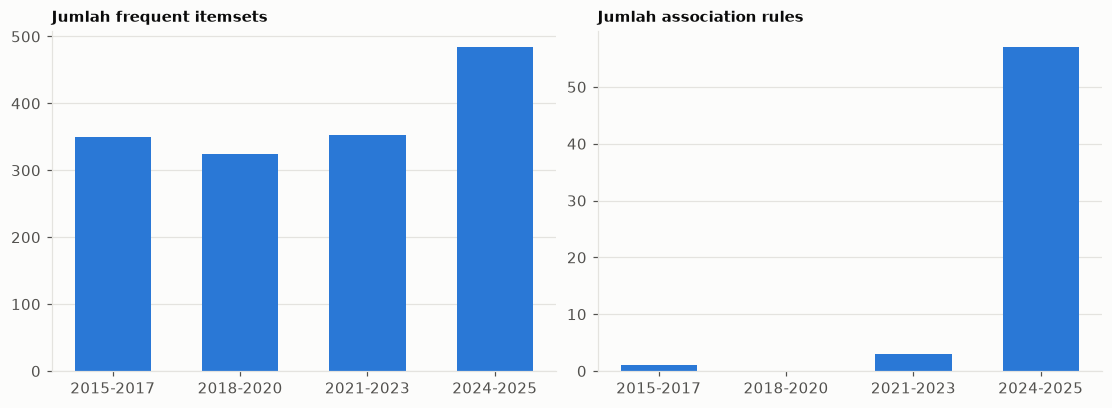

In [3]:
summary = period_summary(results)
summary.insert(2 , "mean_items" , [round(sum(map(len , period_tx[name])) / len(period_tx[name]) , 3) for (name) in (summary["period"])])
display(summary)
print(f"Support = {TEMPORAL_SUPPORT}%, confidence = {TEMPORAL_MIN_CONFIDENCE * 100 :g}%")
fig , axes = plt.subplots(1 , 2 , figsize = (10 , 3.6) , layout = "constrained")
for (ax , column , title) in (zip(axes , ["n_frequent_itemsets" , "n_rules"] , ["Jumlah frequent itemsets" , "Jumlah association rules"])) :
    ax.bar(summary["period"] , summary[column] , color = SERIES[0] , width = 0.6)
    ax.set_title(title , fontsize = 10)
    ax.grid(axis = "x" , visible = False)
save(fig , "07_temporal_counts")
plt.show()

## 3. Frequent Itemsets per Periode

10 kombinasi venue (itemset berukuran ≥ 2) dengan support tertinggi pada setiap periode.

In [4]:
for (name , result) in (results.items()) :
    table = itemsets_frame(result["itemsets"] , result["n_transactions"])
    table = table[table["size"] >= 2].head(10).reset_index(drop = True)
    table.insert(1 , "venue" , [readable(text , names) for (text) in (table["itemset"])])
    print(f"[{name}] {len(result['itemsets'])} frequent itemsets")
    display(table[["itemset" , "venue" , "size" , "support_count" , "support_pct"]])

[2015-2017] 349 frequent itemsets


,itemset,venue,size,support_count,support_pct
0,"[""globecom"", ""icc""]","GLOBECOM, ICC",2,2273,0.246608
1,"[""amcc"", ""cdc""]","ACC, CDC",2,1880,0.203970
2,"[""icra"", ""iros""]","ICRA, IROS",2,1780,0.193121
3,"[""ecoc"", ""ofc""]","ECOC, OFC",2,1720,0.186611
4,"[""aaai"", ""ijcai""]","AAAI, IJCAI",2,1344,0.145817
5,"[""icassp"", ""interspeech""]","ICASSP, INTERSPEECH",2,1296,0.140609
6,"[""icc"", ""vtc""]","ICC, VTC Fall",2,1222,0.132581
7,"[""globecom"", ""vtc""]","GLOBECOM, VTC Fall",2,1167,0.126613
8,"[""cvpr"", ""iccv""]","CVPR, ICCV",2,1138,0.123467


[2018-2020] 324 frequent itemsets


,itemset,venue,size,support_count,support_pct
0,"[""icml"", ""nips""]","ICML, NeurIPS",2,2589,0.239678
1,"[""cvpr"", ""eccv""]","CVPR, ECCV",2,2379,0.220237
2,"[""icra"", ""iros""]","ICRA, IROS",2,2216,0.205148
3,"[""aaai"", ""ijcai""]","AAAI, IJCAI",2,2120,0.196260
4,"[""acl"", ""emnlp""]","ACL, EMNLP",2,2097,0.194131
5,"[""globecom"", ""icc""]","GLOBECOM, ICC",2,2089,0.193390
6,"[""icassp"", ""interspeech""]","ICASSP, INTERSPEECH",2,1947,0.180245
7,"[""iclr"", ""nips""]","ICLR, NeurIPS",2,1737,0.160804
8,"[""aaai"", ""nips""]","AAAI, NeurIPS",2,1638,0.151639
9,"[""cvpr"", ""nips""]","CVPR, NeurIPS",2,1625,0.150435


[2021-2023] 353 frequent itemsets


,itemset,venue,size,support_count,support_pct
0,"[""icml"", ""nips""]","ICML, NeurIPS",2,5426,0.454173
1,"[""acl"", ""emnlp""]","ACL, EMNLP",2,5176,0.433247
2,"[""iclr"", ""nips""]","ICLR, NeurIPS",2,4996,0.418180
3,"[""cvpr"", ""iccv""]","CVPR, ICCV",2,4710,0.394241
4,"[""cvpr"", ""nips""]","CVPR, NeurIPS",2,4508,0.377333
5,"[""aaai"", ""nips""]","AAAI, NeurIPS",2,3816,0.319411
6,"[""iclr"", ""icml""]","ICLR, ICML",2,3047,0.255043
7,"[""icassp"", ""interspeech""]","ICASSP, INTERSPEECH",2,3016,0.252448
8,"[""iccv"", ""nips""]","ICCV, NeurIPS",2,2846,0.238219
9,"[""aaai"", ""cvpr""]","AAAI, CVPR",2,2806,0.234871


[2024-2025] 484 frequent itemsets


,itemset,venue,size,support_count,support_pct
0,"[""iclr"", ""nips""]","ICLR, NeurIPS",2,9224,1.043139
1,"[""icml"", ""nips""]","ICML, NeurIPS",2,8753,0.989874
2,"[""acl"", ""emnlp""]","ACL, EMNLP",2,7144,0.807913
3,"[""cvpr"", ""nips""]","CVPR, NeurIPS",2,6818,0.771045
4,"[""iclr"", ""icml""]","ICLR, ICML",2,6465,0.731125
5,"[""aaai"", ""nips""]","AAAI, NeurIPS",2,6298,0.712239
6,"[""emnlp"", ""nips""]","EMNLP, NeurIPS",2,5106,0.577436
7,"[""acl"", ""nips""]","ACL, NeurIPS",2,5053,0.571442
8,"[""aaai"", ""cvpr""]","AAAI, CVPR",2,4286,0.484702
9,"[""cvpr"", ""iclr""]","CVPR, ICLR",2,4091,0.462650


### Pasangan Venue yang Frequent di Semua Periode

Support (%) pasangan venue yang frequent pada keempat periode.

In [5]:
pairs = [{itemset for (itemset) in (result["itemsets"]) if (len(itemset) == 2)} for (result) in (results.values())]
stable = set.intersection(*pairs)
display(pd.DataFrame([{"venue" : ", ".join(names.get(item , item) for (item) in (sorted(pair))) , **{name : round(100 * result["itemsets"][pair] / result["n_transactions"] , 3) for (name , result) in (results.items())}} for (pair) in (stable)]).sort_values(periods[-1] , ascending = False , ignore_index = True))

,venue,2015-2017,2018-2020,2021-2023,2024-2025
0,"CVPR, ICCV",0.123,0.114,0.394,0.439
1,"ICRA, IROS",0.193,0.205,0.221,0.324
2,"AAAI, IJCAI",0.146,0.196,0.185,0.311
3,"ICASSP, INTERSPEECH",0.141,0.180,0.252,0.231
4,"GLOBECOM, ICC",0.247,0.193,0.201,0.180


## 4. Association Rules per Periode

In [6]:
for (name , result) in (results.items()) :
    print(f"[{name}] {len(result['rules'])} rules, 10 lift tertinggi")
    if (not result["rules"].empty) :
        display(show_rules(result["rules"].head(10)))

[2015-2017] 1 rules, 10 lift tertinggi


,antecedent,consequent,support_count,support_pct,confidence_pct,lift
0,ECOC,OFC,1720,0.1866,51.5897,59.7517


[2018-2020] 0 rules, 10 lift tertinggi
[2021-2023] 3 rules, 10 lift tertinggi


,antecedent,consequent,support_count,support_pct,confidence_pct,lift
0,"ICCV, NeurIPS",CVPR,1603,0.1342,56.3247,30.2704
1,"ICLR, ICML",NeurIPS,1940,0.1624,63.6692,23.2382
2,"CVPR, ICLR",NeurIPS,1203,0.1007,56.2150,20.5175


[2024-2025] 57 rules, 10 lift tertinggi


,antecedent,consequent,support_count,support_pct,confidence_pct,lift
0,"EMNLP, NAACL-HLT, NeurIPS",ACL,899,0.1017,72.3833,29.0233
1,"ACL, NAACL-HLT, NeurIPS",EMNLP,899,0.1017,70.8432,25.4617
2,"ICCV, ICLR, NeurIPS",CVPR,895,0.1012,65.2332,24.3510
3,"EMNLP, ICLR, NeurIPS",ACL,1224,0.1384,59.5910,23.8941
4,"ICLR, NAACL-HLT",ACL,1096,0.1239,58.5783,23.4880
5,"NAACL-HLT, NeurIPS",ACL,1269,0.1435,57.2653,22.9616
6,"EMNLP, NAACL-HLT",ACL,2033,0.2299,57.1228,22.9044
7,"ACL, ICML, NeurIPS",ICLR,1080,0.1221,63.9053,22.6960
8,"COLING, EMNLP",ACL,1394,0.1576,56.5059,22.6570
9,"EMNLP, ICML, NeurIPS",ACL,973,0.1100,56.1778,22.5255


## 5. Perbandingan Rules Antarperiode

- Nilai tabel = lift rule pada setiap periode, `NaN` berarti rule tidak lolos ambang.
- `delta` = lift periode terakhir dikurangi lift periode pertama yang memuat rule.

,status,n_rules
0,Muncul,57
1,Menghilang,1


Rules Bertahan (0)
Rules Muncul (57)


,rule,2015-2017,2018-2020,2021-2023,2024-2025,delta
0,"ICCV, NeurIPS -> CVPR",NaN,NaN,30.270,19.858,-10.412
1,"ICLR, ICML -> NeurIPS",NaN,NaN,23.238,12.096,-11.142
2,"CVPR, ICLR -> NeurIPS",NaN,NaN,20.518,11.953,-8.565
3,"EMNLP, NAACL-HLT, NeurIPS -> ACL",NaN,NaN,NaN,29.023,0.000
4,"ACL, NAACL-HLT, NeurIPS -> EMNLP",NaN,NaN,NaN,25.462,0.000
5,"ICCV, ICLR, NeurIPS -> CVPR",NaN,NaN,NaN,24.351,0.000
6,"EMNLP, ICLR, NeurIPS -> ACL",NaN,NaN,NaN,23.894,0.000
7,"ICLR, NAACL-HLT -> ACL",NaN,NaN,NaN,23.488,0.000
8,"NAACL-HLT, NeurIPS -> ACL",NaN,NaN,NaN,22.962,0.000
9,"EMNLP, NAACL-HLT -> ACL",NaN,NaN,NaN,22.904,0.000


Rules Menghilang (1)


,rule,2015-2017,2018-2020,2021-2023,2024-2025,delta
57,ECOC -> OFC,59.752,NaN,NaN,NaN,0.0


Rules Fluktuatif (0)


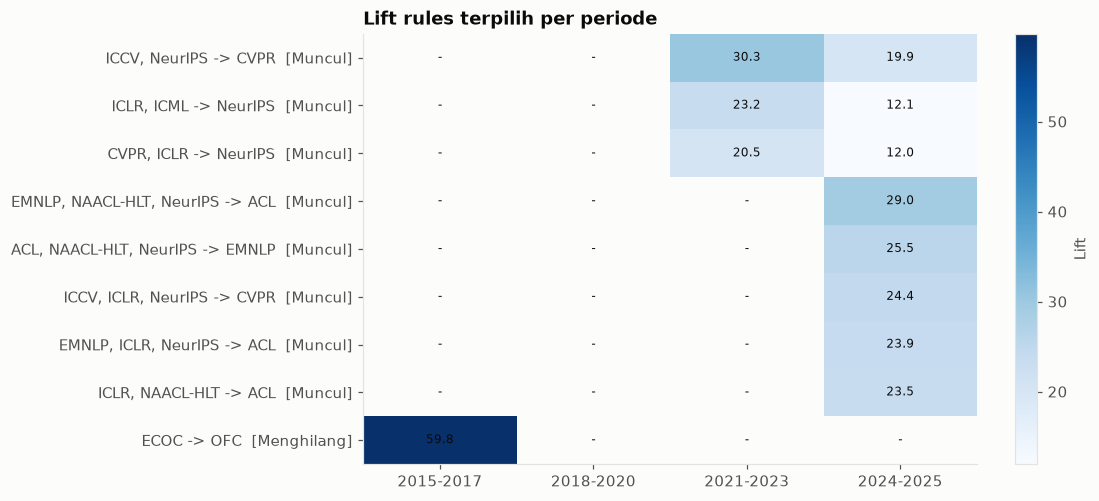

In [7]:
comparison = compare_rules_across_periods(results)
comparison.insert(0 , "rule" , [readable(a , names) + " -> " + readable(c , names) for (a , c) in (zip(comparison["antecedent"] , comparison["consequent"]))])
display(comparison["status"].value_counts().rename_axis("status").reset_index(name = "n_rules"))
for (status) in ("Bertahan" , "Muncul" , "Menghilang" , "Fluktuatif") :
    part = comparison[comparison["status"] == status]
    print(f"Rules {status} ({len(part)})")
    if (not part.empty) :
        display(part.head(10)[["rule" , *periods , "delta"]].round(3))
selected = pd.concat([comparison[comparison["status"] == status].head(8) for (status) in ("Bertahan" , "Muncul" , "Menghilang")])
if (not selected.empty) :
    values = selected[periods].to_numpy(dtype = float)
    fig , ax = plt.subplots(figsize = (9 , 0.42 * len(selected) + 1.3))
    image = ax.imshow(np.ma.masked_invalid(values) , cmap = "Blues" , aspect = "auto")
    ax.set_xticks(range (len(periods)) , periods)
    ax.set_yticks(range (len(selected)) , [f"{rule}  [{status}]" for (rule , status) in (zip(selected["rule"] , selected["status"]))])
    ax.grid(False)
    for (i , j) in (np.ndindex(values.shape)) :
        ax.text(j , i , "-" if (np.isnan(values[i , j])) else f"{values[i , j] :.1f}" , ha = "center" , va = "center" , fontsize = 8)
    fig.colorbar(image , ax = ax).set_label("Lift")
    ax.set_title("Lift rules terpilih per periode")
    save(fig , "07_temporal_rule_lift")
    plt.show()

## 6. Perubahan Support Venue

Support (%) venue yang terlibat pada rule Muncul atau Menghilang, untuk menjelaskan perubahan tren.

,venue_id,venue,2015-2017,2018-2020,2021-2023,2024-2025,delta
0,nips,NeurIPS,0.5113,1.2887,2.7399,4.9448,4.4335
1,iclr,ICLR,0.0715,0.5094,1.1172,2.8157,2.7442
2,emnlp,EMNLP,0.2864,0.7430,1.4720,2.7823,2.4959
3,icml,ICML,0.3251,0.7149,1.2393,2.7140,2.3890
4,aaai,AAAI,0.6752,1.3442,1.7678,2.9175,2.2423
5,acl,ACL,0.3209,0.5965,1.2776,2.4940,2.1730
6,cvpr,CVPR,0.6353,1.1312,1.8607,2.6789,2.0435
7,mm,ACM Multimedia,0.2979,0.4295,0.8741,1.5016,1.2037
8,naacl,NAACL-HLT,0.1344,0.2489,0.3921,1.1367,1.0022
9,iccv,ICCV,0.3799,0.3357,1.2021,1.3576,0.9777


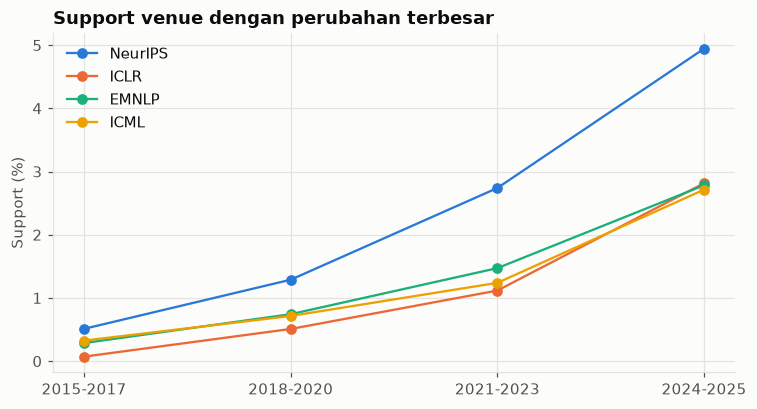

In [8]:
changed = comparison[comparison["status"].isin(["Muncul" , "Menghilang"])]
venues = sorted({venue for (text) in (pd.concat([changed["antecedent"] , changed["consequent"]])) for (venue) in (json.loads(text))})
if (venues) :
    trend = venue_support_trend(period_tx , venues)
    trend["delta"] = trend[periods[-1]] - trend[periods[0]]
    trend = trend.sort_values("delta" , key = abs , ascending = False).reset_index()
    trend.insert(1 , "venue" , [names.get(venue , venue) for (venue) in (trend["venue_id"])])
    display(trend.round(4))
    fig , ax = plt.subplots(figsize = (8 , 4))
    for (i , row) in (trend.head(4).iterrows()) :
        ax.plot(periods , [row[period] for (period) in (periods)] , marker = "o" , color = SERIES[i] , label = row["venue"])
    ax.set_ylabel("Support (%)")
    ax.set_title("Support venue dengan perubahan terbesar")
    ax.legend()
    save(fig , "07_temporal_venue_trend")
    plt.show()
else :
    print("Tidak ada rule yang muncul atau menghilang.")

## 7. Author-Based vs Author-Year-Based

Kedua representasi (2015–2025) ditambang dengan support dan confidence yang sama untuk menjawab Pertanyaan Kesimpulan 5.

In [9]:
representations = compare_representations()
display(period_summary(representations).rename(columns = {"period" : "representation"}))
for (name , result) in (representations.items()) :
    print(f"[{name}] 10 rule dengan lift tertinggi")
    display(show_rules(result["rules"].head(10)))

[Author-Based] 1,817,265 transaksi -> 1462 itemset, 1225 rules


[Author-Year-Based] 4,080,856 transaksi -> 335 itemset, 1 rules


,representation,n_transactions,n_frequent_itemsets,n_frequent_1,n_frequent_2,n_frequent_3,n_frequent_4plus,n_rules
0,Author-Based,1817265,1462,582,386,322,172,1225
1,Author-Year-Based,4080856,335,295,39,1,0,1


[Author-Based] 10 rule dengan lift tertinggi


,antecedent,consequent,support_count,support_pct,confidence_pct,lift
0,"ICLR, NAACL-HLT","ACL, EMNLP, NeurIPS",1885,0.1037,51.0287,155.7224
1,"CVPR, ECCV, ICML","ICCV, ICLR",1832,0.1008,55.2973,153.7012
2,"AAAI, ECCV, ICLR","CVPR, ICCV, NeurIPS",1865,0.1026,65.7385,152.0094
3,"EMNLP, NAACL-HLT, NeurIPS","ACL, ICLR",1885,0.1037,54.4955,149.6642
4,"AAAI, ICCV, ICLR","CVPR, ECCV, NeurIPS",1865,0.1026,53.2857,148.3823
5,"ECCV, ICML, NeurIPS","ICCV, ICLR",1838,0.1011,52.8617,146.9312
6,"ACL, NAACL-HLT, NeurIPS","EMNLP, ICLR",1885,0.1037,56.6576,144.0632
7,"AAAI, CVPR, ICCV, ICLR","ECCV, NeurIPS",1865,0.1026,64.5999,141.2188
8,"AAAI, CVPR, ECCV, NeurIPS","ICCV, ICLR",1865,0.1026,50.7898,141.1723
9,"ECCV, ICCV, ICML","CVPR, ICLR",1832,0.1008,65.4987,137.5099


[Author-Year-Based] 10 rule dengan lift tertinggi


,antecedent,consequent,support_count,support_pct,confidence_pct,lift
0,"ICLR, ICML",NeurIPS,6577,0.1612,60.584,25.9998


## 8. Interpretasi

- **Itemsets dan rules per periode**:
  - Jumlah frequent itemsets = 349 (2015–2017), 324 (2018–2020), 353 (2021–2023), dan 484 (2024–2025).
  - Jumlah 2-itemset naik dari 9 menjadi 18, 42, dan 127, sedangkan 3-itemset baru muncul pada 2021–2023 (3) dan 2024–2025 (51).
  - Jumlah rules (confidence 50%) = 1, 0, 3, dan 57.
  - Hal ini terjadi karena transaksi author-year pendek (rata-rata 1,565–1,689 venue), sehingga dua venue jarang didatangi penulis yang sama pada tahun yang sama. Rata-rata venue per transaksi paling tinggi pada 2024–2025, sehingga kombinasi yang lolos juga paling banyak.
- **Pola yang bertahan**:
  - Tidak ada rule yang muncul di semua periode pada confidence 50%.
  - Pada level frequent itemset, terdapat 5 pasangan venue yang frequent di keempat periode, yaitu GLOBECOM–ICC, ICRA–IROS, AAAI–IJCAI, ICASSP–INTERSPEECH, dan CVPR–ICCV. Kelimanya adalah komunitas venue satu bidang yang stabil.
- **Pola yang berubah**:
  - 57 rule berstatus Muncul. Tiga rule sudah ada sejak 2021–2023 (ICCV, NeurIPS → CVPR; ICLR, ICML → NeurIPS; CVPR, ICLR → NeurIPS), sedangkan 54 rule lainnya baru muncul pada 2024–2025 dan didominasi venue NLP (ACL, EMNLP, NAACL-HLT) bersama NeurIPS dan ICLR.
  - Lift ketiga rule yang sudah ada sejak 2021–2023 turun 8,6–11,1 pada 2024–2025, karena support NeurIPS dan CVPR sebagai consequent naik.
  - 1 rule berstatus Menghilang, yaitu ECOC → OFC (lift 59,75 pada 2015–2017), seiring turunnya support ECOC dari 0,36% menjadi 0,31% (2018–2020) dan 0,10% (2021–2023).
  - Pasangan venue teratas bergeser dari GLOBECOM–ICC (jaringan dan telekomunikasi) pada 2015–2017 menjadi ICML–NeurIPS pada 2018–2023 dan ICLR–NeurIPS pada 2024–2025.
- **Kemungkinan perubahan tren publikasi**:
  - Bidang machine learning dan NLP tumbuh sangat pesat. Support NeurIPS naik dari 0,51% menjadi 4,94%, ICLR dari 0,07% menjadi 2,82%, EMNLP dari 0,29% menjadi 2,78%, dan ACL dari 0,32% menjadi 2,49%.
  - Penulis NLP semakin sering publikasi di venue machine learning pada tahun yang sama, sehingga rule antara ACL / EMNLP dan NeurIPS / ICLR baru muncul pada 2024–2025.
  - Data 2025 kemungkinan belum lengkap, karena jumlah venue pada 2025 hanya 1.888, lebih sedikit daripada 2.381 pada 2024 (`results/tables/publications_per_year.csv`).
- **Author-Based vs Author-Year-Based**:
  - Author-Based = 1.462 itemset dan 1.225 rules, sedangkan Author-Year-Based (seluruh 2015–2025) = 335 itemset dan hanya 1 rule, yaitu ICLR, ICML → NeurIPS (confidence 60,58%, lift 26,0).
  - Contoh nyata = CVPR–ECCV–ICCV adalah 3-itemset teratas ke-4 pada Author-Based, tetapi ICCV hanya diadakan pada tahun ganjil dan ECCV pada tahun genap, sehingga keduanya tidak pernah muncul dalam satu transaksi author-year.
  - Sehingga dapat disimpulkan bahwa asosiasi antar-konferensi lebih banyak terbentuk lintas tahun dalam karier penulis daripada dalam satu tahun yang sama.